<a href="https://colab.research.google.com/github/shashikawka/268452H-CS5998-Capstone-Project/blob/main/04_autoencoder_anomaly_detection_cleaned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 Autoencoder Anomaly Detection (Cleaned Version)

MetroPT-3 railway APU sensor data. This notebook uses **60-observation × 15-feature** windows and a dense autoencoder. It calculates reconstruction errors, evaluates documented failure intervals, and compares the autoencoder with the Isolation Forest baseline at the **same window level**.

**Run mode:** `RETRAIN_MODEL = False` uses the previously saved trained model and **copies** it into a new results folder. No retraining is performed. Change to `True` only if you want a separate new training experiment; results may differ.

**Original results are never overwritten.** All new outputs go to `autoencoder_results_cleaned/`.

## Step 1 - Setup and paths

In [1]:
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import drive

drive.mount('/content/drive')
tf.keras.utils.set_random_seed(42)

project_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT')
data_dir = project_dir / 'processed_data'
baseline_dir = project_dir / 'isolation_forest_results'
original_ae_dir = project_dir / 'autoencoder_results'
cleaned_dir = project_dir / 'autoencoder_results_cleaned'
cleaned_dir.mkdir(parents=True, exist_ok=True)

RETRAIN_MODEL = False  # Keep False to reproduce the original saved model
WINDOW_SIZE = 60
N_FEATURES = 15

print('TensorFlow:', tf.__version__)
print('New output folder:', cleaned_dir)
print('Retrain model:', RETRAIN_MODEL)
assert data_dir.exists(), 'Processed data folder was not found'
assert original_ae_dir.exists(), 'Original autoencoder results folder was not found'

Mounted at /content/drive
TensorFlow: 2.21.0
New output folder: /content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results_cleaned
Retrain model: False


## Step 2 : Load prepared windows and metadata

In [2]:
X_train_windows = np.load(data_dir / 'X_train_windows.npy', mmap_mode='r')
X_val_windows = np.load(data_dir / 'X_val_windows.npy', mmap_mode='r')
X_eval_windows = np.load(data_dir / 'X_eval_windows.npy', mmap_mode='r')

val_metadata = pd.read_csv(data_dir / 'val_metadata.csv', index_col=0, parse_dates=['timestamp'])
eval_metadata = pd.read_csv(data_dir / 'eval_metadata.csv', index_col=0, parse_dates=['timestamp'])
val_window_end_indices = np.load(data_dir / 'val_window_end_indices.npy')
eval_window_end_indices = np.load(data_dir / 'eval_window_end_indices.npy')

for name, windows in [('Train', X_train_windows), ('Validation', X_val_windows), ('Evaluation', X_eval_windows)]:
    print(name, windows.shape, windows.dtype)
    assert windows.shape[1:] == (WINDOW_SIZE, N_FEATURES)
    assert np.isfinite(windows).all(), f'{name} contains non-finite values'

assert len(val_window_end_indices) == len(X_val_windows)
assert len(eval_window_end_indices) == len(X_eval_windows)
assert len(val_metadata) == 139419
assert len(eval_metadata) == 954384

Train (41938, 60, 15) float32
Validation (13749, 60, 15) float32
Evaluation (94307, 60, 15) float32


##### Observation:
##### I loaded the 60-observation windows prepared in Notebook 02.
##### The training, validation and evaluation datasets are kept separate.

## Step 3 : Model architecture and model selection

In [3]:
def build_autoencoder(window_size=60, n_features=15):
    input_dim = window_size * n_features
    model = models.Sequential([
        layers.Input(shape=(window_size, n_features)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(input_dim, activation='linear'),
        layers.Reshape((window_size, n_features))
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

if RETRAIN_MODEL:
    autoencoder = build_autoencoder(WINDOW_SIZE, N_FEATURES)
    first_stage = autoencoder.fit(
        X_train_windows, X_train_windows,
        validation_data=(X_val_windows, X_val_windows),
        epochs=30, batch_size=256, shuffle=True,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True)], verbose=1
    )
    second_stage = autoencoder.fit(
        X_train_windows, X_train_windows,
        validation_data=(X_val_windows, X_val_windows),
        epochs=20, batch_size=256, shuffle=True,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True)], verbose=1
    )
    training_history = {
        'loss': [float(x) for x in first_stage.history['loss'] + second_stage.history['loss']],
        'val_loss': [float(x) for x in first_stage.history['val_loss'] + second_stage.history['val_loss']]
    }
    autoencoder.save(cleaned_dir / 'autoencoder_model.keras')
    with open(cleaned_dir / 'training_history.json', 'w') as f:
        json.dump(training_history, f, indent=2)
    model_source = 'newly_trained'
else:
    source_model = original_ae_dir / 'autoencoder_model.keras'
    assert source_model.exists(), 'Saved original model is missing'
    shutil.copy2(source_model, cleaned_dir / 'autoencoder_model.keras')
    autoencoder = tf.keras.models.load_model(cleaned_dir / 'autoencoder_model.keras')
    history_source = original_ae_dir / 'training_history.json'
    if history_source.exists():
        shutil.copy2(history_source, cleaned_dir / 'training_history.json')
    model_source = 'copied_original_model'

print('Model source:', model_source)
print('Trainable parameters:', autoencoder.count_params())
autoencoder.summary()
assert autoencoder.input_shape[1:] == (60, 15)
assert autoencoder.output_shape[1:] == (60, 15)
assert autoencoder.count_params() == 252196

Model source: copied_original_model
Trainable parameters: 252196


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 900)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       115,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 900)            │       116,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 60, 15)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 756,590 (2.89 MB)

 Trainable params: 252,196 (985.14 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 504,394 (1.92 MB)

##### Observation:
##### I used a dense autoencoder with a 32-neuron bottleneck.
##### It reconstructs each full window but does not explicitly model time order like an LSTM.
##### By default, this cleaned notebook reuses the previously trained model.

## Step 4 : Plot training history

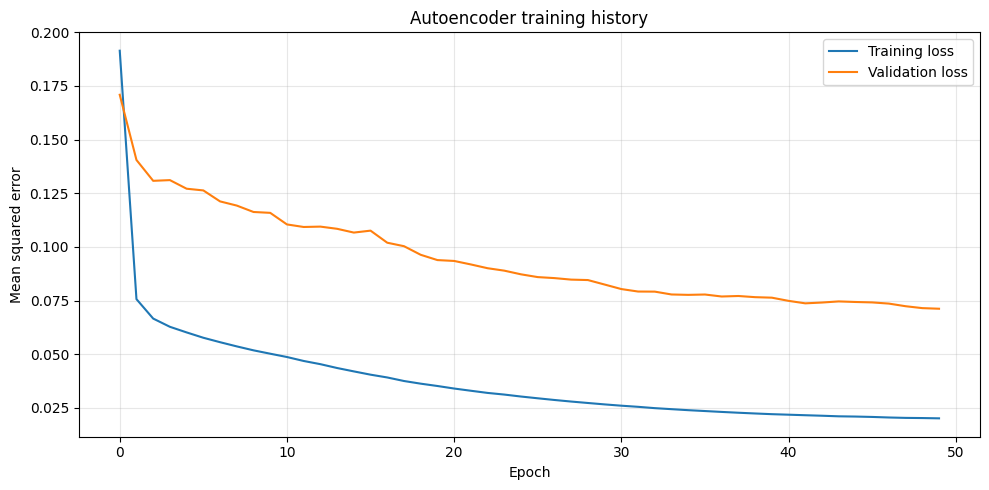

Recorded epochs: 50
Lowest recorded validation loss: 0.07117723673582077


In [4]:
history_path = cleaned_dir / 'training_history.json'
if history_path.exists():
    with open(history_path) as f:
        training_history = json.load(f)
    plt.figure(figsize=(10, 5))
    plt.plot(training_history['loss'], label='Training loss')
    plt.plot(training_history['val_loss'], label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Mean squared error')
    plt.title('Autoencoder training history')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(cleaned_dir / 'training_validation_loss.png', dpi=200, bbox_inches='tight')
    plt.show()
    print('Recorded epochs:', len(training_history['loss']))
    print('Lowest recorded validation loss:', min(training_history['val_loss']))
else:
    print('No saved training history found.')

##### Observation:
##### I plotted the training history stored with the model.
##### When I reuse the saved model, this is the original training history.

## Step 5 : Recalculate reconstruction errors with the saved model

In [5]:
def calculate_reconstruction_errors(model, windows, batch_size=256):
    errors = []
    for start in range(0, len(windows), batch_size):
        batch = np.asarray(windows[start:start + batch_size], dtype=np.float32)
        reconstructed = model.predict(batch, verbose=0)
        errors.append(np.mean((batch - reconstructed) ** 2, axis=(1, 2)))
    return np.concatenate(errors)

train_errors = calculate_reconstruction_errors(autoencoder, X_train_windows)
val_errors = calculate_reconstruction_errors(autoencoder, X_val_windows)
eval_errors = calculate_reconstruction_errors(autoencoder, X_eval_windows)

for name, errors in [('train', train_errors), ('val', val_errors), ('eval', eval_errors)]:
    np.save(cleaned_dir / f'{name}_errors.npy', errors)
    print(name, errors.shape, 'mean:', round(float(errors.mean()), 6))

train (41938,) mean: 0.019797
val (13749,) mean: 0.071177
eval (94307,) mean: 0.116357


##### Observation:
##### I calculated one mean squared reconstruction error for each window.
##### I saved the three error arrays in the cleaned results folder.

## Step 6 : Check error distributions

         Training  Validation  Evaluation
count  41938.0000  13749.0000  94307.0000
mean       0.0198      0.0712      0.1164
std        0.0436      0.2260      0.3504
min        0.0004      0.0004      0.0004
25%        0.0007      0.0011      0.0052
50%        0.0056      0.0107      0.0279
75%        0.0267      0.0425      0.0596
max        1.3935      5.7972      5.3711


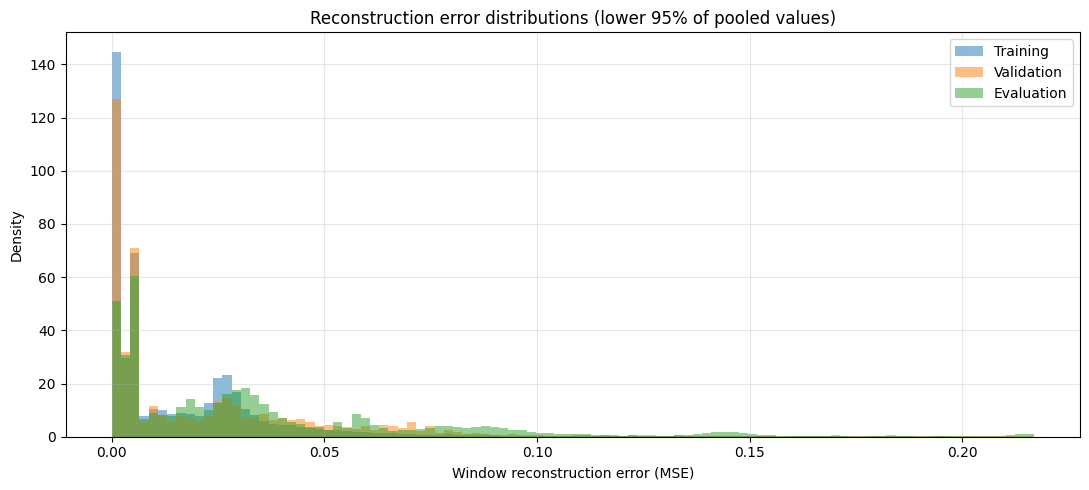

In [6]:
error_summary = pd.DataFrame({
    'Training': pd.Series(train_errors),
    'Validation': pd.Series(val_errors),
    'Evaluation': pd.Series(eval_errors)
})
print(error_summary.describe().round(4))

plot_limit = np.percentile(np.concatenate([train_errors, val_errors, eval_errors]), 95)
plt.figure(figsize=(11, 5))
for name, values in [('Training', train_errors), ('Validation', val_errors), ('Evaluation', eval_errors)]:
    plt.hist(values, bins=100, range=(0, plot_limit), density=True, alpha=0.5, label=name)
plt.title('Reconstruction error distributions (lower 95% of pooled values)')
plt.xlabel('Window reconstruction error (MSE)')
plt.ylabel('Density')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(cleaned_dir / 'reconstruction_error_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

##### Observation:
##### The training errors are generally lower than the validation and evaluation errors.
##### I limited the plot range to make the main distributions easier to see.

## Step 7 : Set the autoencoder threshold using validation windows

In [7]:
ae_threshold = float(np.percentile(val_errors, 99))
train_predictions = train_errors > ae_threshold
val_predictions = val_errors > ae_threshold
eval_predictions = eval_errors > ae_threshold

np.save(cleaned_dir / 'ae_threshold.npy', ae_threshold)
for name, values in [('train', train_predictions), ('val', val_predictions), ('eval', eval_predictions)]:
    np.save(cleaned_dir / f'{name}_predictions.npy', values)
    print(name, int(values.sum()), f'({values.mean() * 100:.2f}%)')
print('AE threshold:', round(ae_threshold, 6))
assert val_predictions.sum() in (137, 138, 139)

train 12 (0.03%)
val 138 (1.00%)
eval 4376 (4.64%)
AE threshold: 0.937345


##### Observation:
##### I selected the anomaly threshold from the 99th percentile of validation errors.
##### I did not use the evaluation failure periods to choose the threshold.

## Step 8 : Match windows with their ending timestamps

In [8]:
assert np.isin(eval_window_end_indices, eval_metadata.index).all()
eval_window_metadata = eval_metadata.loc[eval_window_end_indices].copy()
eval_window_metadata['reconstruction_error'] = eval_errors
eval_window_metadata['ae_anomaly'] = eval_predictions
assert len(eval_window_metadata) == len(eval_errors)
eval_window_metadata.to_csv(cleaned_dir / 'eval_window_results.csv', index=True)
print('Evaluation window metadata:', eval_window_metadata.shape)
display(eval_window_metadata.head())

Evaluation window metadata: (94307, 5)


,timestamp,segment_id,failure_period,reconstruction_error,ae_anomaly
562623,2020-04-18 00:11:52,112,1,0.079310,False
562633,2020-04-18 00:13:53,112,1,0.078905,False
562643,2020-04-18 00:15:54,112,1,0.079388,False
562653,2020-04-18 00:17:55,112,1,0.075551,False
562714,2020-04-18 00:33:44,113,1,1.157577,True


##### Observation:
##### The window ending indices use the original dataset index labels.
##### I used .loc[] to match each window with its ending timestamp.

## Step 9 : Evaluate the documented failure periods

In [9]:
failure_periods = [
    ('Failure 1', '2020-04-18 00:00:00', '2020-04-18 23:59:00'),
    ('Failure 2', '2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    ('Failure 3', '2020-06-05 10:00:00', '2020-06-07 14:30:00'),
    ('Failure 4', '2020-07-15 14:30:00', '2020-07-15 19:00:00')
]

failure_mask = np.zeros(len(eval_window_metadata), dtype=bool)
failure_results = []
detection_results = []
for name, start, end in failure_periods:
    start_time, end_time = pd.Timestamp(start), pd.Timestamp(end)
    mask = eval_window_metadata['timestamp'].between(start_time, end_time).to_numpy()
    failure_mask |= mask
    subset = eval_window_metadata.loc[mask].sort_values('timestamp')
    flagged = subset.loc[subset['ae_anomaly']]
    failure_results.append({
        'Failure': name, 'Total Windows': len(subset),
        'Anomalous Windows': len(flagged),
        'Anomaly Percentage': round(100 * len(flagged) / len(subset), 2) if len(subset) else np.nan
    })
    first = flagged['timestamp'].iloc[0] if len(flagged) else pd.NaT
    delay = (first - start_time).total_seconds() / 60 if pd.notna(first) else np.nan
    detection_results.append({
        'Failure': name, 'Status': 'Detected' if len(flagged) else 'Not Detected',
        'First Detection': first,
        'Detection Delay (minutes)': round(delay, 2) if pd.notna(delay) else np.nan
    })

failure_results_df = pd.DataFrame(failure_results)
detection_results_df = pd.DataFrame(detection_results)
failure_results_df.to_csv(cleaned_dir / 'failure_results.csv', index=False)
detection_results_df.to_csv(cleaned_dir / 'detection_timing.csv', index=False)
display(failure_results_df)
display(detection_results_df)

inside_rate = 100 * eval_predictions[failure_mask].mean()
outside_rate = 100 * eval_predictions[~failure_mask].mean()
print(f'Inside documented failure intervals: {inside_rate:.2f}%')
print(f'Outside documented failure intervals: {outside_rate:.2f}%')

,Failure,Total Windows,Anomalous Windows,Anomaly Percentage
0,Failure 1,855,851,99.53
1,Failure 2,236,236,100.00
2,Failure 3,1719,1719,100.00
3,Failure 4,156,0,0.00


,Failure,Status,First Detection,Detection Delay (minutes)
0,Failure 1,Detected,2020-04-18 00:33:44,33.73
1,Failure 2,Detected,2020-05-29 23:30:37,0.62
2,Failure 3,Detected,2020-06-05 10:01:23,1.38
3,Failure 4,Not Detected,NaT,NaN


Inside documented failure intervals: 94.61%
Outside documented failure intervals: 1.72%


##### Observation:
##### I checked the percentage of anomalous windows in each documented failure interval.
##### These are window-level anomaly rates, not confirmed point-level recall scores.
##### A window is assigned to an interval using its ending timestamp.

## Step 10 : Check anomalies in the 24 hours before failures

In [10]:
pre_failure_results = []
for name, start, end in failure_periods:
    start_time = pd.Timestamp(start)
    mask = (
        (eval_window_metadata['timestamp'] >= start_time - pd.Timedelta(hours=24)) &
        (eval_window_metadata['timestamp'] < start_time)
    )
    subset = eval_window_metadata.loc[mask].sort_values('timestamp')
    flagged = subset.loc[subset['ae_anomaly']]
    last = flagged['timestamp'].iloc[-1] if len(flagged) else pd.NaT
    minutes_before = (start_time - last).total_seconds() / 60 if pd.notna(last) else np.nan
    pre_failure_results.append({
        'Failure': name, 'Total Windows': len(subset),
        'Anomalous Windows': len(flagged),
        'Anomaly Percentage': round(100 * len(flagged) / len(subset), 2) if len(subset) else np.nan,
        'Last Anomaly Before Failure': last,
        'Minutes Before Failure': round(minutes_before, 2) if pd.notna(minutes_before) else np.nan
    })
pre_failure_results_df = pd.DataFrame(pre_failure_results)
pre_failure_results_df.to_csv(cleaned_dir / 'pre_failure_results.csv', index=False)
display(pre_failure_results_df)

,Failure,Total Windows,Anomalous Windows,Anomaly Percentage,Last Anomaly Before Failure,Minutes Before Failure
0,Failure 1,0,0,NaN,NaT,NaN
1,Failure 2,731,8,1.09,2020-05-29 23:28:58,1.03
2,Failure 3,872,5,0.57,2020-06-05 09:59:44,0.27
3,Failure 4,613,16,2.61,2020-07-15 13:32:51,57.15


##### Observation:
##### Some anomalous windows appeared before the documented failure start times.
##### These alone do not establish reliable advance failure prediction.

## Step 11 : Examine pre-failure alerts for Failure 4

,timestamp,reconstruction_error
1166437,2020-07-15 01:40:43,1.427241
1167857,2020-07-15 05:35:21,1.128745
1168697,2020-07-15 07:54:09,1.168786
1168957,2020-07-15 08:37:06,3.111244
1168967,2020-07-15 08:38:46,2.579277
1169107,2020-07-15 09:01:54,1.060199
1169117,2020-07-15 09:03:33,1.003346
1169157,2020-07-15 09:10:09,1.045709
1169407,2020-07-15 09:51:28,1.180918
1169427,2020-07-15 09:54:46,1.556483


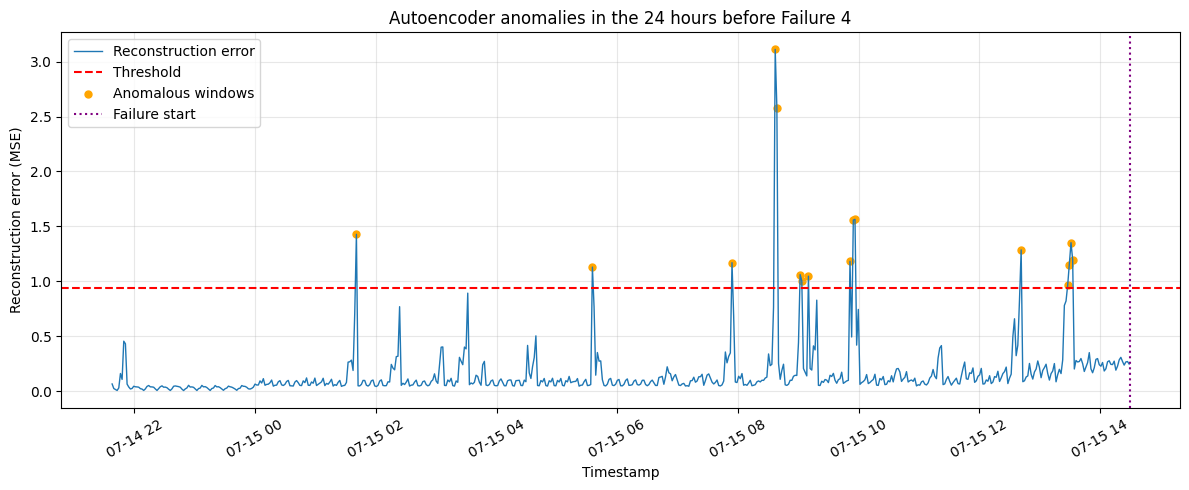

In [11]:
failure_4_start = pd.Timestamp('2020-07-15 14:30:00')
failure_4_pre = eval_window_metadata.loc[
    (eval_window_metadata['timestamp'] >= failure_4_start - pd.Timedelta(hours=24)) &
    (eval_window_metadata['timestamp'] < failure_4_start)
].sort_values('timestamp').copy()
failure_4_alerts = failure_4_pre.loc[failure_4_pre['ae_anomaly']].copy()
failure_4_alerts.to_csv(cleaned_dir / 'failure_4_pre_failure_alerts.csv', index=True)
display(failure_4_alerts[['timestamp', 'reconstruction_error']])

plt.figure(figsize=(12, 5))
plt.plot(failure_4_pre['timestamp'], failure_4_pre['reconstruction_error'], label='Reconstruction error', linewidth=1)
plt.axhline(ae_threshold, color='red', linestyle='--', label='Threshold')
plt.scatter(failure_4_alerts['timestamp'], failure_4_alerts['reconstruction_error'], s=25, color='orange', label='Anomalous windows')
plt.axvline(failure_4_start, color='purple', linestyle=':', label='Failure start')
plt.title('Autoencoder anomalies in the 24 hours before Failure 4')
plt.xlabel('Timestamp')
plt.ylabel('Reconstruction error (MSE)')
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(cleaned_dir / 'failure_4_pre_failure_anomalies.png', dpi=200, bbox_inches='tight')
plt.show()

##### Observation:
##### I examined the timing of anomalies before Failure 4.
##### These alerts need more investigation before being treated as early warnings.

## Step 12 : Fair window-level comparison with Isolation Forest

### Step 12.1 : Load row-level baseline scores

In [12]:
if_val_scores = np.load(baseline_dir / 'val_scores.npy')
if_eval_scores = np.load(baseline_dir / 'eval_scores.npy')
assert len(if_val_scores) == len(val_metadata)
assert len(if_eval_scores) == len(eval_metadata)
print('IF validation rows:', len(if_val_scores))
print('IF evaluation rows:', len(if_eval_scores))

IF validation rows: 139419
IF evaluation rows: 954384


### Step 12.2 : Aggregate scores over exactly the same windows

In [13]:
def calculate_if_window_scores(row_scores, metadata, window_end_indices, window_size=60):
    assert len(row_scores) == len(metadata)
    assert 'segment_id' in metadata.columns, 'Expected segment_id in metadata'
    assert metadata.index.is_unique
    end_positions = metadata.index.get_indexer(window_end_indices)
    assert (end_positions >= 0).all(), 'Window end indices missing from metadata'
    start_positions = end_positions - window_size + 1
    assert (start_positions >= 0).all()

    segment_ids = metadata['segment_id'].to_numpy()
    assert np.array_equal(segment_ids[start_positions], segment_ids[end_positions]), 'Window crosses a segment boundary'

    # Check original row labels are consecutive throughout each window.
    # This also checks the assumptions used to reconstruct the window boundaries.
    labels = metadata.index.to_numpy()
    assert np.issubdtype(labels.dtype, np.integer), 'Expected integer original row indices'
    assert np.array_equal(labels[end_positions] - labels[start_positions],
                          np.full(len(end_positions), window_size - 1)), 'Unexpected row index gaps'

    cumulative = np.concatenate(([0.0], np.cumsum(row_scores, dtype=np.float64)))
    return (cumulative[end_positions + 1] - cumulative[start_positions]) / window_size

if_val_window_scores = calculate_if_window_scores(if_val_scores, val_metadata, val_window_end_indices)
if_eval_window_scores = calculate_if_window_scores(if_eval_scores, eval_metadata, eval_window_end_indices)
assert len(if_val_window_scores) == len(val_errors)
assert len(if_eval_window_scores) == len(eval_errors)

np.save(cleaned_dir / 'if_val_window_scores.npy', if_val_window_scores)
np.save(cleaned_dir / 'if_eval_window_scores.npy', if_eval_window_scores)
print('IF validation windows:', if_val_window_scores.shape)
print('IF evaluation windows:', if_eval_window_scores.shape)

IF validation windows: (13749,)
IF evaluation windows: (94307,)


##### Observation:
##### I averaged the Isolation Forest scores across the same 60-observation windows.
##### I checked that each window stays inside one recording segment and has consecutive row indices.

### Step 12.3 : Select the baseline window threshold

In [14]:
if_window_threshold = float(np.percentile(if_val_window_scores, 99))
if_val_window_predictions = if_val_window_scores > if_window_threshold
if_eval_window_predictions = if_eval_window_scores > if_window_threshold
np.save(cleaned_dir / 'if_window_threshold.npy', if_window_threshold)
np.save(cleaned_dir / 'if_val_window_predictions.npy', if_val_window_predictions)
np.save(cleaned_dir / 'if_eval_window_predictions.npy', if_eval_window_predictions)

print('IF threshold:', round(if_window_threshold, 6))
print('AE threshold:', round(ae_threshold, 6))
print('IF validation anomalies:', int(if_val_window_predictions.sum()))
print('AE validation anomalies:', int(val_predictions.sum()))
print('IF evaluation anomalies:', int(if_eval_window_predictions.sum()))
print('AE evaluation anomalies:', int(eval_predictions.sum()))

IF threshold: 0.700428
AE threshold: 0.937345
IF validation anomalies: 138
AE validation anomalies: 138
IF evaluation anomalies: 3205
AE evaluation anomalies: 4376


##### Observation:
##### Both models use the 99th percentile of their own validation window scores.
##### The thresholds have different numerical scales.

### Step 12.4 : Compare detection rates in each failure interval

In [15]:
comparison_df = eval_metadata.loc[eval_window_end_indices].copy()
comparison_df['if_score'] = if_eval_window_scores
comparison_df['if_anomaly'] = if_eval_window_predictions
comparison_df['ae_score'] = eval_errors
comparison_df['ae_anomaly'] = eval_predictions
comparison_df.to_csv(cleaned_dir / 'window_level_model_comparison.csv', index=True)

comparison_rows = []
for name, start, end in failure_periods:
    subset = comparison_df.loc[comparison_df['timestamp'].between(pd.Timestamp(start), pd.Timestamp(end))]
    comparison_rows.append({
        'Period': name,
        'Windows': len(subset),
        'IF Anomalous Windows': int(subset['if_anomaly'].sum()),
        'IF Anomaly Rate (%)': round(100 * subset['if_anomaly'].mean(), 2),
        'AE Anomalous Windows': int(subset['ae_anomaly'].sum()),
        'AE Anomaly Rate (%)': round(100 * subset['ae_anomaly'].mean(), 2)
    })

outside = comparison_df.loc[~failure_mask]
comparison_rows.append({
    'Period': 'Outside documented failures', 'Windows': len(outside),
    'IF Anomalous Windows': int(outside['if_anomaly'].sum()),
    'IF Anomaly Rate (%)': round(100 * outside['if_anomaly'].mean(), 2),
    'AE Anomalous Windows': int(outside['ae_anomaly'].sum()),
    'AE Anomaly Rate (%)': round(100 * outside['ae_anomaly'].mean(), 2)
})
comparison_summary_df = pd.DataFrame(comparison_rows)
comparison_summary_df.to_csv(cleaned_dir / 'failure_period_model_comparison.csv', index=False)
display(comparison_summary_df)

,Period,Windows,IF Anomalous Windows,IF Anomaly Rate (%),AE Anomalous Windows,AE Anomaly Rate (%)
0,Failure 1,855,6,0.70,851,99.53
1,Failure 2,236,219,92.80,236,100.00
2,Failure 3,1719,1716,99.83,1719,100.00
3,Failure 4,156,31,19.87,0,0.00
4,Outside documented failures,91341,1233,1.35,1570,1.72


##### Observation:
##### I compared the models using the same evaluation windows and failure intervals.
##### Higher failure-period anomaly rates can be useful, but alerts outside the intervals
##### cannot automatically be called false alarms because those windows are not fully labelled.

## Step 13 : Save experiment information and verify output files

In [16]:
experiment_info = {
    'model_source': model_source,
    'original_model_path': str(original_ae_dir / 'autoencoder_model.keras'),
    'cleaned_output_path': str(cleaned_dir),
    'window_size': WINDOW_SIZE,
    'feature_count': N_FEATURES,
    'threshold_percentile': 99,
    'ae_threshold': ae_threshold,
    'if_window_threshold': if_window_threshold,
    'train_windows': int(len(train_errors)),
    'validation_windows': int(len(val_errors)),
    'evaluation_windows': int(len(eval_errors)),
    'note': 'Documented failure intervals are weak reference labels; results are window-level anomaly rates.'
}
with open(cleaned_dir / 'experiment_info.json', 'w') as f:
    json.dump(experiment_info, f, indent=2)

required_files = [
    'autoencoder_model.keras', 'train_errors.npy', 'val_errors.npy', 'eval_errors.npy',
    'ae_threshold.npy', 'train_predictions.npy', 'val_predictions.npy', 'eval_predictions.npy',
    'failure_results.csv', 'detection_timing.csv', 'pre_failure_results.csv',
    'eval_window_results.csv', 'failure_4_pre_failure_alerts.csv',
    'if_val_window_scores.npy', 'if_eval_window_scores.npy',
    'if_window_threshold.npy', 'if_val_window_predictions.npy', 'if_eval_window_predictions.npy',
    'window_level_model_comparison.csv', 'failure_period_model_comparison.csv',
    'experiment_info.json'
]
missing = [filename for filename in required_files if not (cleaned_dir / filename).exists()]
print('Missing files:', missing)
assert not missing, 'Some results were not saved'

# These checks are specific to the original trained model, not a new retraining run.
if not RETRAIN_MODEL:
    original_ae_threshold = float(np.load(original_ae_dir / 'ae_threshold.npy'))
    original_eval_predictions = np.load(original_ae_dir / 'eval_predictions.npy')
    print('AE threshold matches original:', np.isclose(ae_threshold, original_ae_threshold, rtol=1e-5))
    print('AE predictions match original:', np.array_equal(eval_predictions, original_eval_predictions))
    assert np.isclose(ae_threshold, original_ae_threshold, rtol=1e-5)
    assert np.array_equal(eval_predictions, original_eval_predictions)

print('Cleaned experiment completed. Original results were not modified.')

Missing files: []
AE threshold matches original: True
AE predictions match original: True
Cleaned experiment completed. Original results were not modified.


## Notes for the report

- The autoencoder is a **dense window-based reconstruction model**, not an LSTM.
- Both models use a validation-based **99th percentile threshold**, but their anomaly scores have different scales.
- The Isolation Forest baseline scores are **averaged over each matching window**. This aligns evaluation units but does not make the model architectures identical.
- The failure intervals are **weak reference labels**. A flagged window outside a documented interval is not necessarily a false positive.
- The pre-failure alerts are exploratory; they do not by themselves prove predictive lead time.
- The default run **copies the existing model** and recalculates outputs. It is not a new independently trained model.